Завантаження та розпакування датасету

In [1]:
from ultralytics.data.utils import check_det_dataset

print("Завантаження VisDrone через внутрішній механізм Ultralytics...")
# Ця функція сама знайде актуальне посилання і завантажить датасет
dataset_info = check_det_dataset('VisDrone.yaml')

dataset_path = dataset_info['path']
print(f"Датасет успішно завантажено! Абсолютний шлях: {dataset_path}")

Завантаження VisDrone через внутрішній механізм Ultralytics...
Датасет успішно завантажено! Абсолютний шлях: /home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone


Фільтрація класів (Data Engineering)
Тепер ми маємо відфільтрувати ці згенеровані мітки, щоб залишити лише транспорт (автомобілі, фургони, вантажівки, автобуси), і створити конфіг. Код пройдеться по всіх файлах розмітки, видалить зайві класи (пішоходи, велосипеди тощо) і перепризначить ID для транспорту від 0 до 3.

In [2]:
import os
import glob

try:
    base_dir = dataset_path 
except NameError:
    base_dir = '/home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone'

# Словник: {старий_id: новий_id} (car, van, truck, bus)
target_classes = {3: 0, 4: 1, 5: 2, 8: 3} 
kept_count, removed_count = 0, 0

print(f"Шукаю мітки YOLO у директорії: {base_dir}")

# Рекурсивно шукаємо всі .txt файли у датасеті
all_txt_files = glob.glob(os.path.join(base_dir, '**', '*.txt'), recursive=True)

# Відкидаємо файли з оригінальними анотаціями VisDrone (вони не у форматі YOLO)
yolo_txt_files = [f for f in all_txt_files if 'annotations' not in f and not f.endswith('readme.txt')]

print(f"Знайдено {len(yolo_txt_files)} файлів для перевірки. Починаю фільтрацію...")

for txt_file in yolo_txt_files:
    with open(txt_file, 'r') as f:
        lines = f.readlines()
    
    new_lines = []
    for line in lines:
        # Формат YOLO: id x_center y_center width height (розділені пробілом)
        parts = line.strip().split()
        
        # Перевіряємо, чи це точно формат YOLO (мінімум 5 значень)
        if len(parts) < 5: 
            continue 
            
        try:
            class_id = int(parts[0])
            if class_id in target_classes:
                # Замінюємо старий ID на новий
                parts[0] = str(target_classes[class_id])
                new_lines.append(' '.join(parts) + '\n')
                kept_count += 1
            else:
                removed_count += 1
        except ValueError:
            continue # Якщо перший елемент не число, пропускаємо рядок
    
    # Перезаписуємо файл лише з потрібними класами
    with open(txt_file, 'w') as f:
        f.writelines(new_lines)
        
print(f"\n--- РЕЗУЛЬТАТ ---")
print(f"Готово! Залишено об'єктів техніки (авто, фургони, вантажівки, автобуси): {kept_count}.")
print(f"Видалено зайвих об'єктів (пішоходи, велосипеди тощо): {removed_count}.")

Шукаю мітки YOLO у директорії: /home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone
Знайдено 8629 файлів для перевірки. Починаю фільтрацію...

--- РЕЗУЛЬТАТ ---
Готово! Залишено об'єктів техніки (авто, фургони, вантажівки, автобуси): 9117.
Видалено зайвих об'єктів (пішоходи, велосипеди тощо): 235991.


Створення конфігурації (YAML)

In [3]:
import os

try:
    base_dir = dataset_path 
except NameError:
    base_dir = '/home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone'

# Оновлені шляхи: images/train та images/val
yaml_content = f"""
path: {base_dir}
train: images/train
val: images/val
test: images/test

names:
  0: car
  1: van
  2: truck
  3: bus
"""

yaml_path = 'custom_data.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content.strip())

print("Конфігурацію оновлено під нову структуру папок!")

Конфігурацію оновлено під нову структуру папок!


Візуалізація DefTech аугментацій
Беремо одне випадкове фото з датасету і накладає на нього специфічні для БПЛА спотворення: розмиття в русі (MotionBlur), шум матриці (GaussNoise) та зміну освітлення.

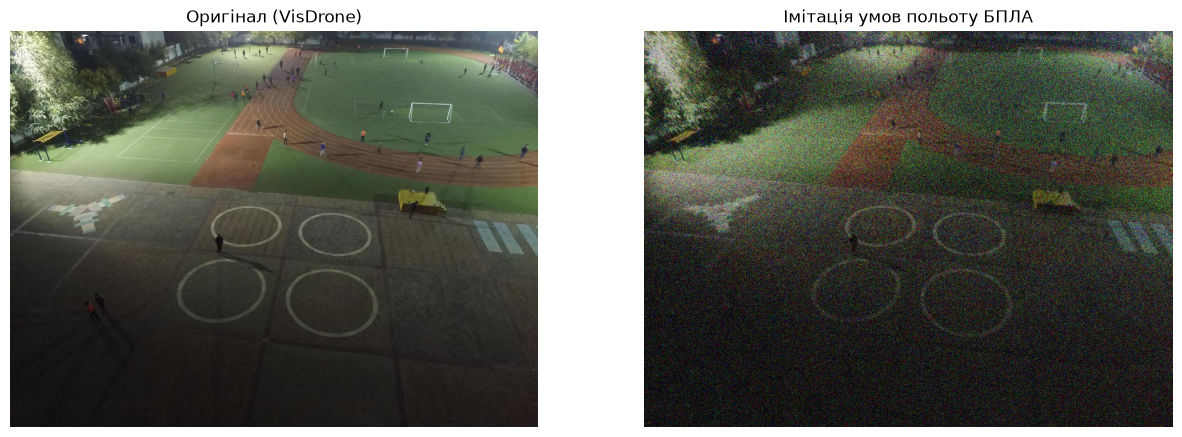

In [4]:
import cv2
import random
import glob
import matplotlib.pyplot as plt
import albumentations as A
import os

# Оновлений пайплайн без застарілих параметрів
drone_transform = A.Compose([
    A.MotionBlur(blur_limit=15, p=1.0),
    A.GaussNoise(p=1.0), # Прибрали var_limit, щоб не було Warning
    A.RandomBrightnessContrast(p=1.0)
])

try:
    base_dir = dataset_path 
except NameError:
    base_dir = '/home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone'

# Правильний шлях згідно зі структурою
images = glob.glob(os.path.join(base_dir, 'images', 'train', '*.jpg'))

if images:
    sample_img = cv2.imread(random.choice(images))
    sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

    # Застосовуємо аугментацію
    augmented = drone_transform(image=sample_img)['image']

    # Візуалізуємо
    fig, ax = plt.subplots(1, 2, figsize=(15, 7))
    ax[0].imshow(sample_img)
    ax[0].set_title("Оригінал (VisDrone)")
    ax[0].axis('off')
    
    ax[1].imshow(augmented)
    ax[1].set_title("Імітація умов польоту БПЛА")
    ax[1].axis('off')
    
    plt.show()
else:
    print(f"Зображення не знайдено за шляхом: {os.path.join(base_dir, 'images', 'train', '*.jpg')}")

Запуск тренування YOLO11n

In [5]:
from ultralytics import YOLO

# Завантажуємо базову Nano модель
model = YOLO('yolo11n.pt')

print("Починаємо навчання YOLO11n на RTX 2060...")

# Запускаємо процес тренування
results = model.train(
    data='custom_data.yaml',
    epochs=15,               # Кількість епох для міні-проєкту
    imgsz=640,               # Роздільна здатність, оптимальна для YOLO
    batch=16,                # 16 ідеально поміститься у 6GB VRAM
    device=0,                # Використовуємо відеокарту GPU 0
    project='drone_tracking',# Папка, куди збережуться результати
    name='yolo11n_v1',       # Назва експерименту
    # Специфічні гіперпараметри для дронів:
    mosaic=1.0,              # Мозаїка чудово працює для дрібних об'єктів
    mixup=0.1,               # Допомагає при перекритті техніки
    degrees=10.0             # Додаємо легкі нахили (камера дрона нестабільна)
)

print("Тренування успішно завершено! Ваги збережено у drone_tracking/yolo11n_v1/weights/best.pt")

Починаємо навчання YOLO11n на RTX 2060...
Ultralytics 8.4.208 🚀 Python-3.14.4 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=custom_data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_v1-2, n

Інференс та візуалізація передбачень

Завантаження найкращих ваг моделі з runs/detect/drone_tracking/yolo11n_v1-2/weights/best.pt...
Робимо інференс на: 9999938_00000_d_0000495.jpg

image 1/1 /home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone/images/test/9999938_00000_d_0000495.jpg: 384x640 3 cars, 32.3ms
Speed: 4.9ms preprocess, 32.3ms inference, 10.7ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /home/andre/AIagents_projects/aerial_target_detection/runs/detect/runs/detect/drone_tracking/inference_results-3


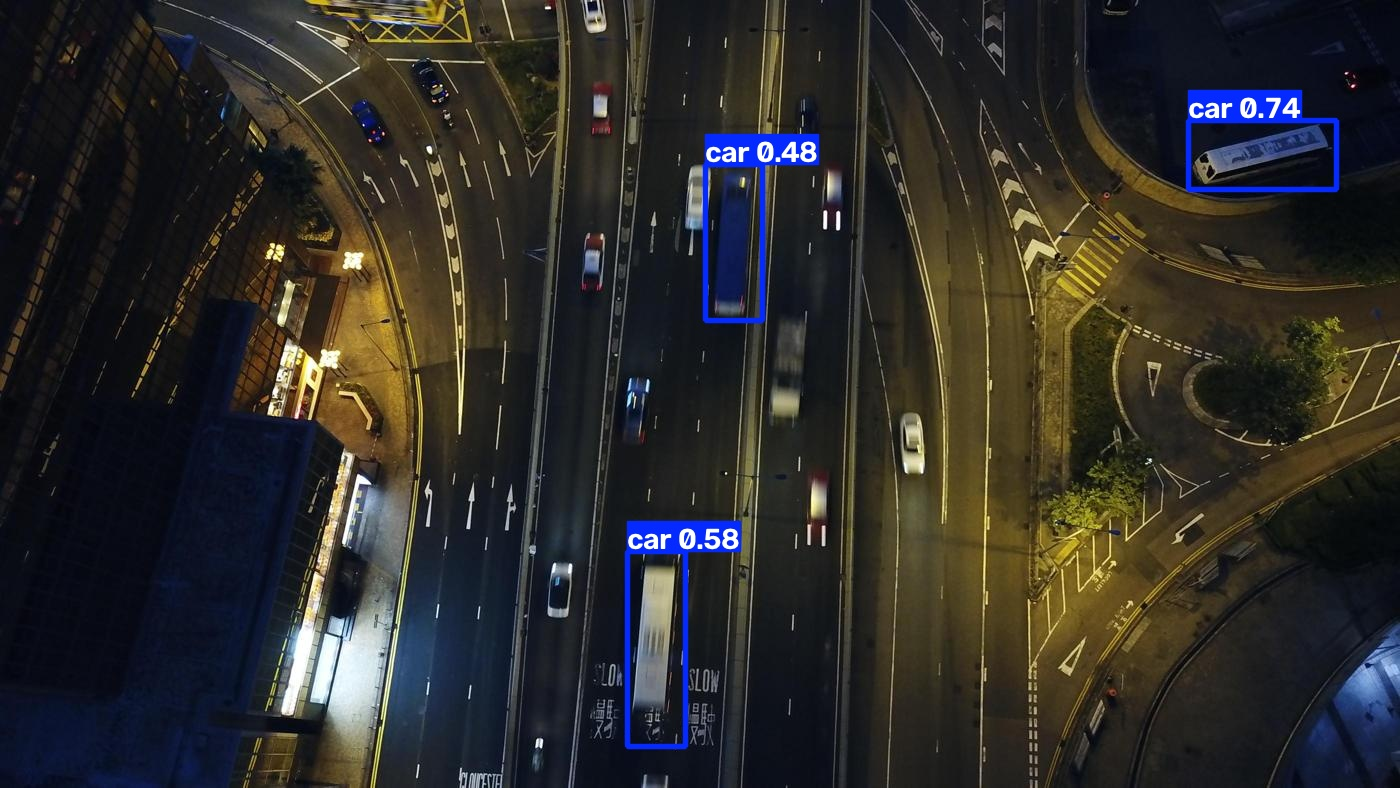

In [10]:
import os
import glob
import random
from IPython.display import Image, display
from ultralytics import YOLO

# Використовуємо фактичний шлях з ваших логів
model_path = 'runs/detect/drone_tracking/yolo11n_v1-2/weights/best.pt'
print(f"Завантаження найкращих ваг моделі з {model_path}...")
best_model = YOLO(model_path)

try:
    base_dir = dataset_path 
except NameError:
    # Ваш шлях до датасету (з попередніх кроків)
    base_dir = '/home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone'

# Шукаємо фото у тестовій вибірці
test_images = glob.glob(os.path.join(base_dir, 'images', 'test', '*.jpg'))

if test_images:
    test_img = random.choice(test_images)
    print(f"Робимо інференс на: {os.path.basename(test_img)}")
    
    # predict з порогом впевненості 25%
    results = best_model.predict(
        source=test_img, 
        conf=0.25, 
        save=True, 
        project="runs/detect/drone_tracking", 
        name="inference_results"
    )
    
    # Виводимо зображення з намальованими рамками
    res_path = results[0].save_dir
    display(Image(filename=os.path.join(res_path, os.path.basename(test_img))))
else:
    print("Тестові зображення не знайдено.")

Експорт моделі у формат ONNX

In [7]:
print("Починаємо експорт моделі в ONNX...")

# simplify=True оптимізує математичний граф моделі для прискорення
export_path = best_model.export(
    format="onnx", 
    imgsz=640, 
    opset=12,
    simplify=True 
)

print(f"Експорт успішно завершено! Модель готова до розгортання: {export_path}")

Починаємо експорт моделі в ONNX...
Ultralytics 8.4.208 🚀 Python-3.14.4 torch-2.15.0+cu132 CPU (Intel Core i5-9300H 2.40GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'runs/detect/drone_tracking/yolo11n_v1-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (5.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...

   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [onnxslim]
   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [onnxslim]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnxslim]


requirements: AutoUpdate success ✅ 2.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99.

Перевірка ONNX моделі (Proof of Work)

In [11]:
# Шлях до скомпільованого .onnx файлу
onnx_model_path = 'runs/detect/drone_tracking/yolo11n_v1-2/weights/best.onnx'

if os.path.exists(onnx_model_path):
    print(f"Завантаження ONNX моделі з {onnx_model_path}...")
    onnx_model = YOLO(onnx_model_path)
    
    if test_images:
         print("Тестування інференсу через ONNX Runtime...")
         onnx_results = onnx_model.predict(source=test_img, imgsz=640)
         print("Перевірка пройдена: ONNX граф працює коректно!")
else:
    print("Файл ONNX не знайдено. Перевірте попередній крок.")

Завантаження ONNX моделі з runs/detect/drone_tracking/yolo11n_v1-2/weights/best.onnx...
Тестування інференсу через ONNX Runtime...
Loading runs/detect/drone_tracking/yolo11n_v1-2/weights/best.onnx for ONNX Runtime inference...
Failed to load libcurand.so.10: libcurand.so.10: cannot open shared object file: No such file or directory
Please follow https://onnxruntime.ai/docs/install/#cuda-and-cudnn to install CUDA.
Using ONNX Runtime 1.31.1 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...

image 1/1 /home/andre/dl_projects/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/notebooks/datasets/VisDrone/images/test/9999938_00000_d_0000495.jpg: 640x640 4 cars, 77.6ms
Speed: 3.1ms preprocess, 77.6ms inference, 27.2ms postprocess per image at shape (1, 3, 640, 640)
Перевірка пройдена: ONNX граф працює коректно!


2026-11-09 21:04:18.444983671 [E:onnxruntime:Default, provider_bridge_ort.cc:2458 operator()] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:2043 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library /home/andre/AIagents_projects/aerial_target_detection/venv/lib/python3.14/site-packages/onnxruntime/capi/libonnxruntime_providers_cuda.so with error: libcurand.so.10: cannot open shared object file: No such file or directory

